In [2]:
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("StudentPerformance.csv")
print(data.shape)

(1000, 8)


In [15]:
print(data.columns)

Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='str')


In [16]:
print(data.head(10))

   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   
5  female        group B          associate's degree      standard   
6  female        group B                some college      standard   
7    male        group B                some college  free/reduced   
8    male        group D                 high school  free/reduced   
9  female        group B                 high school  free/reduced   

  test preparation course  math score  reading score  writing score  
0                    none        72.0           72.0           74.0  
1               completed        69.0           90.0           88.0  
2                  

In [17]:
print(data.describe())

       math score  reading score  writing score
count  998.000000     998.000000     998.000000
mean    66.074148      69.149299      68.057114
std     15.174628      14.577870      15.198709
min      0.000000      17.000000      10.000000
25%     57.000000      59.000000      58.000000
50%     66.000000      70.000000      69.000000
75%     77.000000      79.000000      79.000000
max    100.000000     100.000000     100.000000


In [18]:
print(data.info())

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   gender                       1000 non-null   str    
 1   race/ethnicity               999 non-null    str    
 2   parental level of education  1000 non-null   str    
 3   lunch                        1000 non-null   str    
 4   test preparation course      999 non-null    str    
 5   math score                   998 non-null    float64
 6   reading score                998 non-null    float64
 7   writing score                998 non-null    float64
dtypes: float64(3), str(5)
memory usage: 62.6 KB
None


In [23]:
selec_rows = data.loc[data["math score"] > 97, ["gender", "math score"]]
print(selec_rows)

     gender  math score
104    male        98.0
114  female        99.0
149    male       100.0
263  female        99.0
306    male        99.0
451  female       100.0
458  female       100.0
623    male       100.0
625    male       100.0
712  female        98.0
916    male       100.0
934    male        98.0
962  female       100.0


In [69]:
print(data.isnull().sum())

gender                         0
race/ethnicity                 1
parental level of education    0
lunch                          0
test preparation course        1
math score                     2
reading score                  2
writing score                  2
dtype: int64


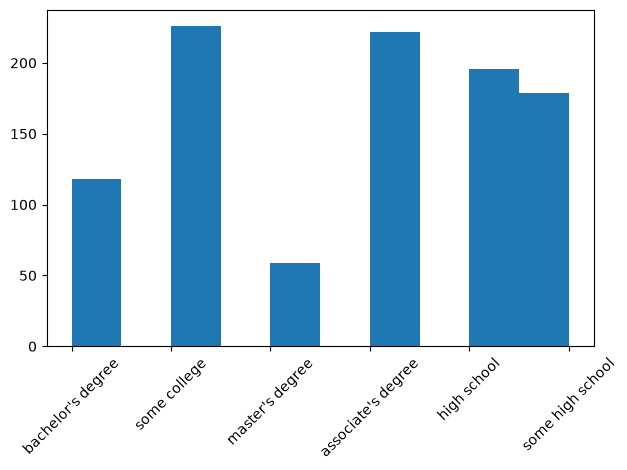

In [66]:
#Univariate Analysis ->only a single variable at a time. 

plt.hist(data["parental level of education"])  # used for numerical data, To show the distribution and shape of a dataset
plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()

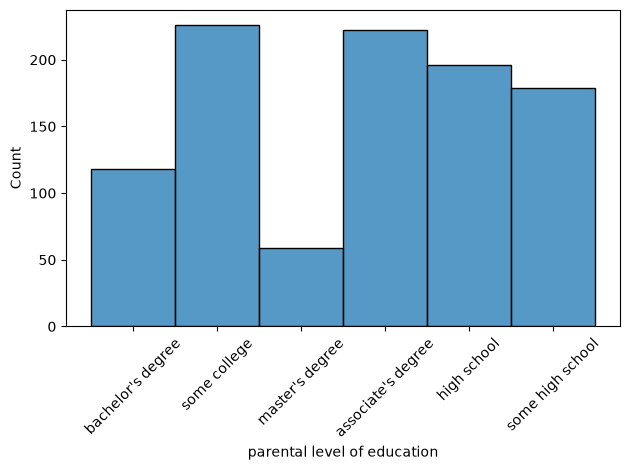

In [46]:
sns.histplot(data["parental level of education"])
plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()

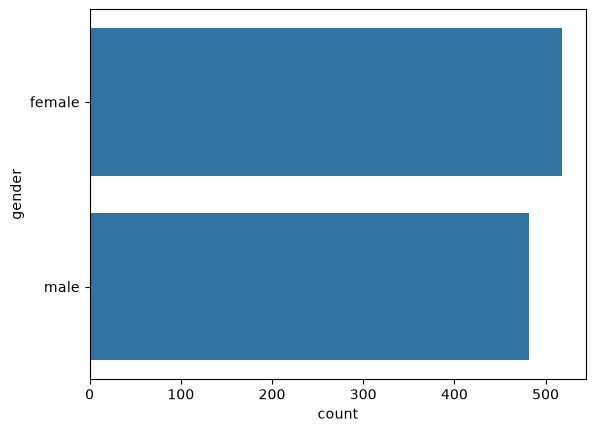

In [6]:
import seaborn as sns
sns.countplot(data["gender"]) # to display no of counts for categorical data ->bar chart
plt.show()

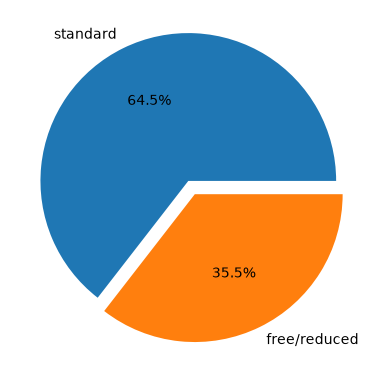

In [63]:
x = data["lunch"].value_counts()  # to decide a portion for each category
myexplode = [0.1, 0]
plt.pie(x.values, labels = x.index, autopct='%1.1f%%', explode = myexplode) #used to compare the percentage or share of different categories in a dataset.
plt.show()

In [97]:
# 1. loading and inspecting data
# 2. Handling missing data

In [107]:
print(data[data["math score"].isnull()].index)

data["math score"] = data["math score"].fillna(data["math score"].mean())

RangeIndex(start=0, stop=0, step=1)


In [111]:
print(data["math score"].loc[369])

66.07414829659318


In [90]:
print(data.isnull().sum())

gender                         0
race/ethnicity                 1
parental level of education    0
lunch                          0
test preparation course        1
math score                     0
reading score                  2
writing score                  2
dtype: int64


In [102]:
data["reading score"] = data["reading score"].interpolate(method='linear')
print(data.isnull().sum())

gender                         0
race/ethnicity                 1
parental level of education    0
lunch                          0
test preparation course        1
math score                     0
reading score                  0
writing score                  2
dtype: int64


In [105]:
print(data[data["writing score"].isnull()].index)

RangeIndex(start=563, stop=587, step=12)


In [109]:
data["writing score"] = data["writing score"].interpolate(method='linear')
print(data.loc[563])

gender                               female
race/ethnicity                      group D
parental level of education    some college
lunch                          free/reduced
test preparation course           completed
math score                             63.0
reading score                          80.0
writing score                          69.0
Name: 563, dtype: object


In [112]:
print(data.isnull().sum())

gender                         0
race/ethnicity                 1
parental level of education    0
lunch                          0
test preparation course        1
math score                     0
reading score                  0
writing score                  0
dtype: int64


In [118]:
data["race/ethnicity"] = data["race/ethnicity"].fillna(data["race/ethnicity"].mode()[0]) #selects first value from mode result series

In [119]:
print(data.isnull().sum())

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        1
math score                     0
reading score                  0
writing score                  0
dtype: int64


In [120]:
print(data[data["test preparation course"].isnull()].index)

RangeIndex(start=366, stop=367, step=1)


In [123]:
data["test preparation course"] = data["test preparation course"].fillna(data["test preparation course"].mode()[0])

In [124]:
print(data.loc[366])

gender                                male
race/ethnicity                     group C
parental level of education    high school
lunch                             standard
test preparation course               none
math score                            69.0
reading score                         58.0
writing score                         53.0
Name: 366, dtype: object


In [125]:
print(data.isnull().sum())

gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64


In [126]:
print(data["gender"].nunique())

2


In [127]:
# Explore data characteristics using different graphs

<Axes: >

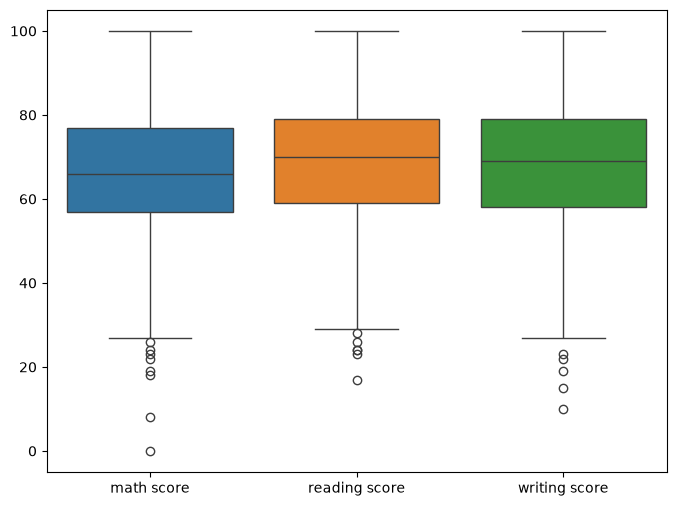

In [9]:
#for outliers
plt.figure(figsize=(8,6))
sns.boxplot(data)

Best approach is to split data before performing normalization & standardization

1. Train - Test Split

In [20]:
from sklearn.model_selection import train_test_split

#data.columns
#correlation = data['math score'].corr(data['reading score'])
#print(f"Correlation: {correlation}")

x = data[["math score","reading score"]]  #selects multiple columns and returns dataframe
y = data["writing score"]
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size = 0.2, random_state = 42)  #80% - 20%

print(data.shape)
print("X_train: ", x_train.shape)
print("X_test: ", x_test.shape)
print(len(y_train))

(1000, 8)
X_train:  (800, 2)
X_test:  (200, 2)
800


2. Train Validation Test Split

In [23]:
x_train, x_temp, y_train, y_temp = train_test_split(x,y, test_size= 0.2, random_state= 10)
x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size = 0.5, random_state = 40) # stratify = y_temp
# stratify ensures balanced division of all classes / records in any for any rare cases. 
print(data.shape)
print("X_train: ", x_train.shape)
print("X_val: ", x_val.shape)
print("X_test: ", x_test.shape)

(1000, 8)
X_train:  (800, 2)
X_val:  (100, 2)
X_test:  (100, 2)


1. Normalization

In [27]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
data["math score"] = scaler.fit_transform(data[["math score"]])

print(data["math score"].head())

0    0.72
1    0.69
2    0.90
3    0.47
4    0.76
Name: math score, dtype: float64


2. Standardization

In [31]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
data["math score"] = scaler.fit_transform(data[["math score"]])

print(data["math score"].head())
mean = data["math score"].mean()
print("mean:", mean)

0    0.390706
1    0.192909
2    1.577492
3   -1.257607
4    0.654436
Name: math score, dtype: float64
mean: 3.2038500109423356e-17


Categorical Data Encoding

In [33]:
# label encoding ->assigns random integers
from sklearn.preprocessing import LabelEncoder
data = ['Civic', 'Toyota', 'Kia', 'Lancruiser', 'Civic', 'Kia']
encoder = LabelEncoder()
encoded_data = encoder.fit_transform(data)
print(encoded_data)

[0 3 1 2 0 1]


In [34]:
# One hot encoding -> converts categories into binary columns
data = ['Red', 'Blue', 'Green', 'Red']

df = pd.DataFrame(data, columns=['Color'])
one_hot_encoded = pd.get_dummies(df['Color'])  #used to convert categorical variables into dummy variables

print(one_hot_encoded)

    Blue  Green    Red
0  False  False   True
1   True  False  False
2  False   True  False
3  False  False   True


In [35]:
# Ordinal Encoder -> maps categories to integers while preserving their natural order.
from sklearn.preprocessing import OrdinalEncoder
data = [['Low'], ['Medium'], ['High'], ['Medium'], ['Low']]

encoder = OrdinalEncoder(categories=[['Low', 'Medium', 'High']])
encoded_data = encoder.fit_transform(data)

print(f"Encoded Ordinal Data: {encoded_data}")

Encoded Ordinal Data: [[0.]
 [1.]
 [2.]
 [1.]
 [0.]]
